# 01 — Analyse exploratoire (EDA) et tests statistiques
**Projet Data Mining — Prédiction du départ des employés (Employee Attrition)**

**Questions guides**
1. Les données sont-elles propres et exploitables ?
2. Comment sont distribuées les variables, et la cible est-elle équilibrée ?
3. Quelles variables sont associées au départ (`Attrition`), et **avec quelle intensité** ?
4. Y a-t-il de la redondance entre variables (colinéarité) qui influencera le choix des modèles ?

**Convention.** Analyse menée sur les 10 000 lignes nettoyées pour maximiser la puissance statistique. Aucune sélection de variables n'en découle (toutes sont conservées) : il n'y a donc pas de fuite vers l'évaluation des modèles. Toute sélection future se fera sur le train uniquement.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.preprocessing import *
from src.stats_tests import *

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = ROOT / "results";            RES.mkdir(exist_ok=True)
BLUE, ORANGE = "#8fb8de", "#d9822b"
sns.set_theme(style="whitegrid")
pd.options.display.float_format = lambda x: f"{x:.4g}"
pd.options.display.width = 200
def savefig(name): plt.savefig(FIG / name, dpi=150, bbox_inches="tight")

df, report = clean_data(load_raw(ROOT / "data" / "raw" / "Employee_Attrition_DataSet.csv"))
QUANT = NUMERIC_COLS + ORDINAL_COLS            # variables mesurées / ordinales
CATEG = NOMINAL_COLS + BINARY_COLS             # variables qualitatives
print(df.shape, "| doublons retirés :", report["duplicate_rows_removed"], "| hors plage :", report["out_of_range_to_nan"])

(10000, 14) | doublons retirés : 0 | hors plage : {}


## 1. Statistiques descriptives
Tendance centrale (moyenne, médiane), dispersion (écart-type, IQR, coefficient de variation) et forme (asymétrie).

In [2]:
d = df[QUANT].describe().T
d["IQR"] = d["75%"] - d["25%"]
d["CV (%)"] = d["std"] / d["mean"] * 100
d["asymétrie"] = df[QUANT].skew()
d.to_csv(RES / "descriptive_stats.csv")
d

,count,mean,std,min,25%,50%,75%,max,IQR,CV (%),asymétrie
Age,1e+04,37.69,9.376,22,31,37,44,60,13,24.88,0.1978
YearsAtCompany,1e+04,7.788,7.142,0,2,6,12,35,10,91.7,1.027
MonthlyIncome,1e+04,8968,3501,3000,6044,8670,1.148e+04,2.141e+04,5440,39.04,0.5399
DistanceFromHome,1e+04,9.911,6.975,1,4.7,8.3,13.4,50,8.7,70.37,1.345
TrainingHoursLastYear,1e+04,14.99,3.886,2,12,15,18,31,6,25.92,0.2603
JobLevel,1e+04,2.381,1.141,1,1,2,3,5,2,47.94,0.3712
JobSatisfaction,1e+04,3.362,1.06,1,3,3,4,5,1,31.53,-0.2533
WorkLifeBalance,1e+04,2.761,0.893,1,2,3,3,4,1,32.34,-0.343
PerformanceRating,1e+04,2.604,0.7379,1,2,3,3,4,1,28.34,0.02813


In [3]:
# Variables qualitatives : effectifs et mode
q = pd.DataFrame({
    "modalités": df[CATEG].nunique(),
    "mode": df[CATEG].agg(lambda s: s.mode().iloc[0]),
    "fréquence du mode (%)": df[CATEG].agg(lambda s: s.value_counts(normalize=True).iloc[0] * 100),
})
q

,modalités,mode,fréquence du mode (%)
Department,7,Sales,24.53
OverTime,2,0,71.51
PromotionLast5Years,2,0,90.86


**Lecture.** `Age` (CV ≈ 25 %) et `TrainingHoursLastYear` (≈ 26 %) sont peu dispersés et quasi symétriques (moyenne ≈ médiane). `YearsAtCompany` (CV ≈ 92 %) et `DistanceFromHome` (≈ 70 %) sont très dispersés et asymétriques à droite : quelques valeurs élevées tirent la moyenne au-dessus de la médiane (7,8 contre 6 ans ; 9,9 contre 8,3 km).

## 2. Valeurs manquantes

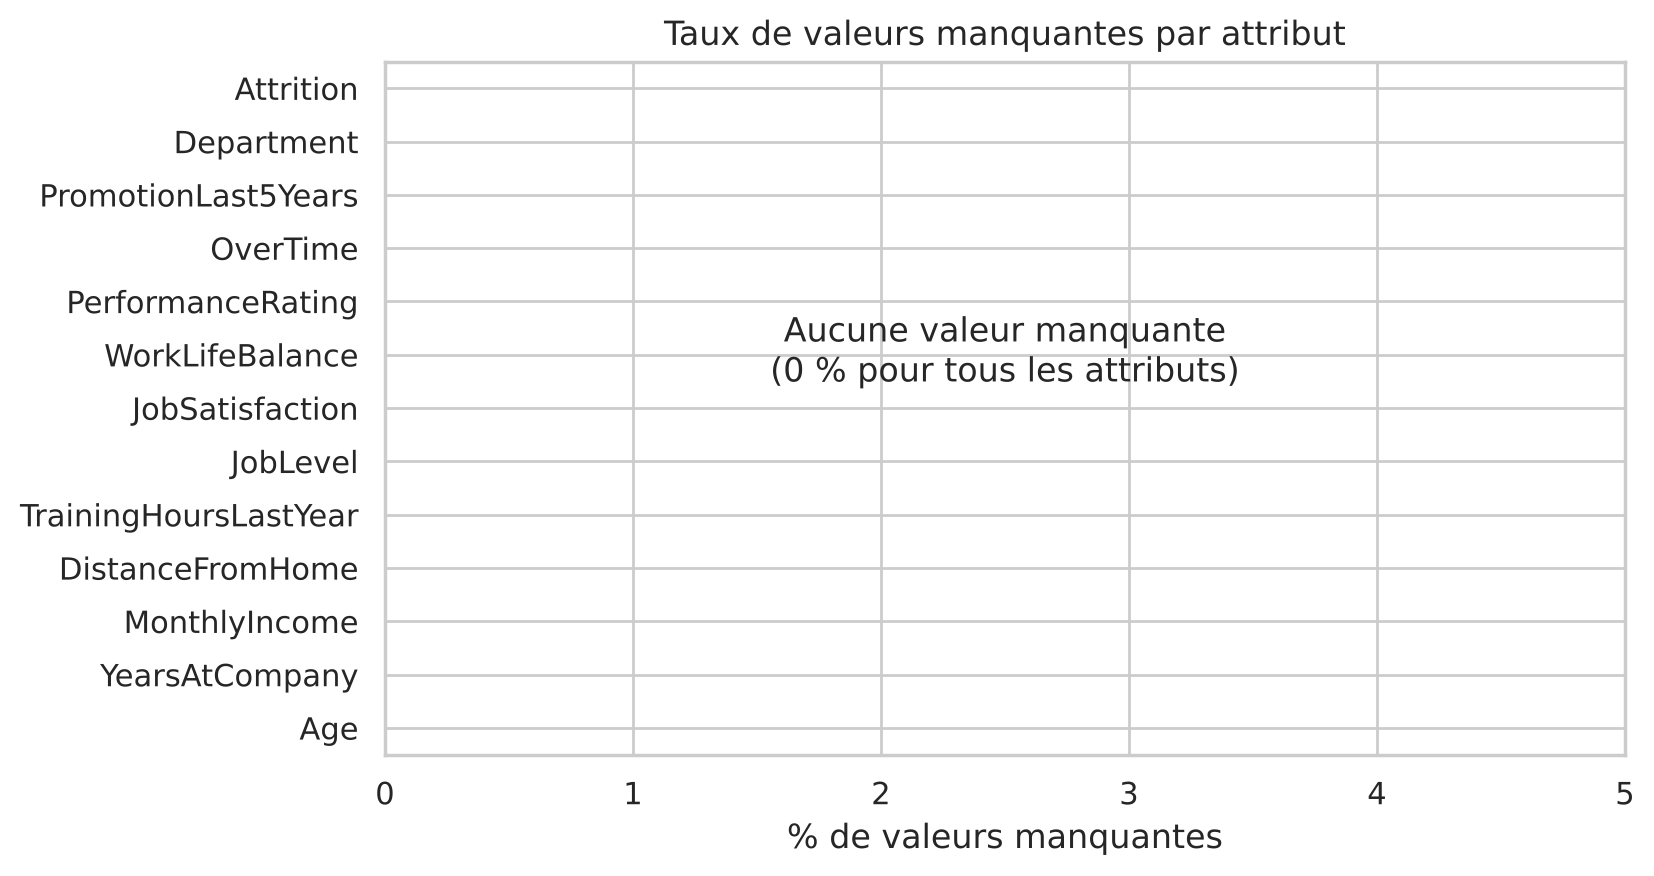

Total de valeurs manquantes : 0


In [4]:
miss = (df[FEATURE_COLS + [TARGET]].isna().mean() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
miss.plot.barh(ax=ax, color=ORANGE); ax.set_xlim(0, 5)
ax.set_xlabel("% de valeurs manquantes"); ax.set_title("Taux de valeurs manquantes par attribut")
ax.text(2.5, len(miss) / 2, "Aucune valeur manquante\n(0 % pour tous les attributs)", ha="center", fontsize=12)
savefig("01_missing_values.png"); plt.show()
print("Total de valeurs manquantes :", int(df.isna().sum().sum()))

## 3. Distributions des variables numériques (histogramme + densité KDE)

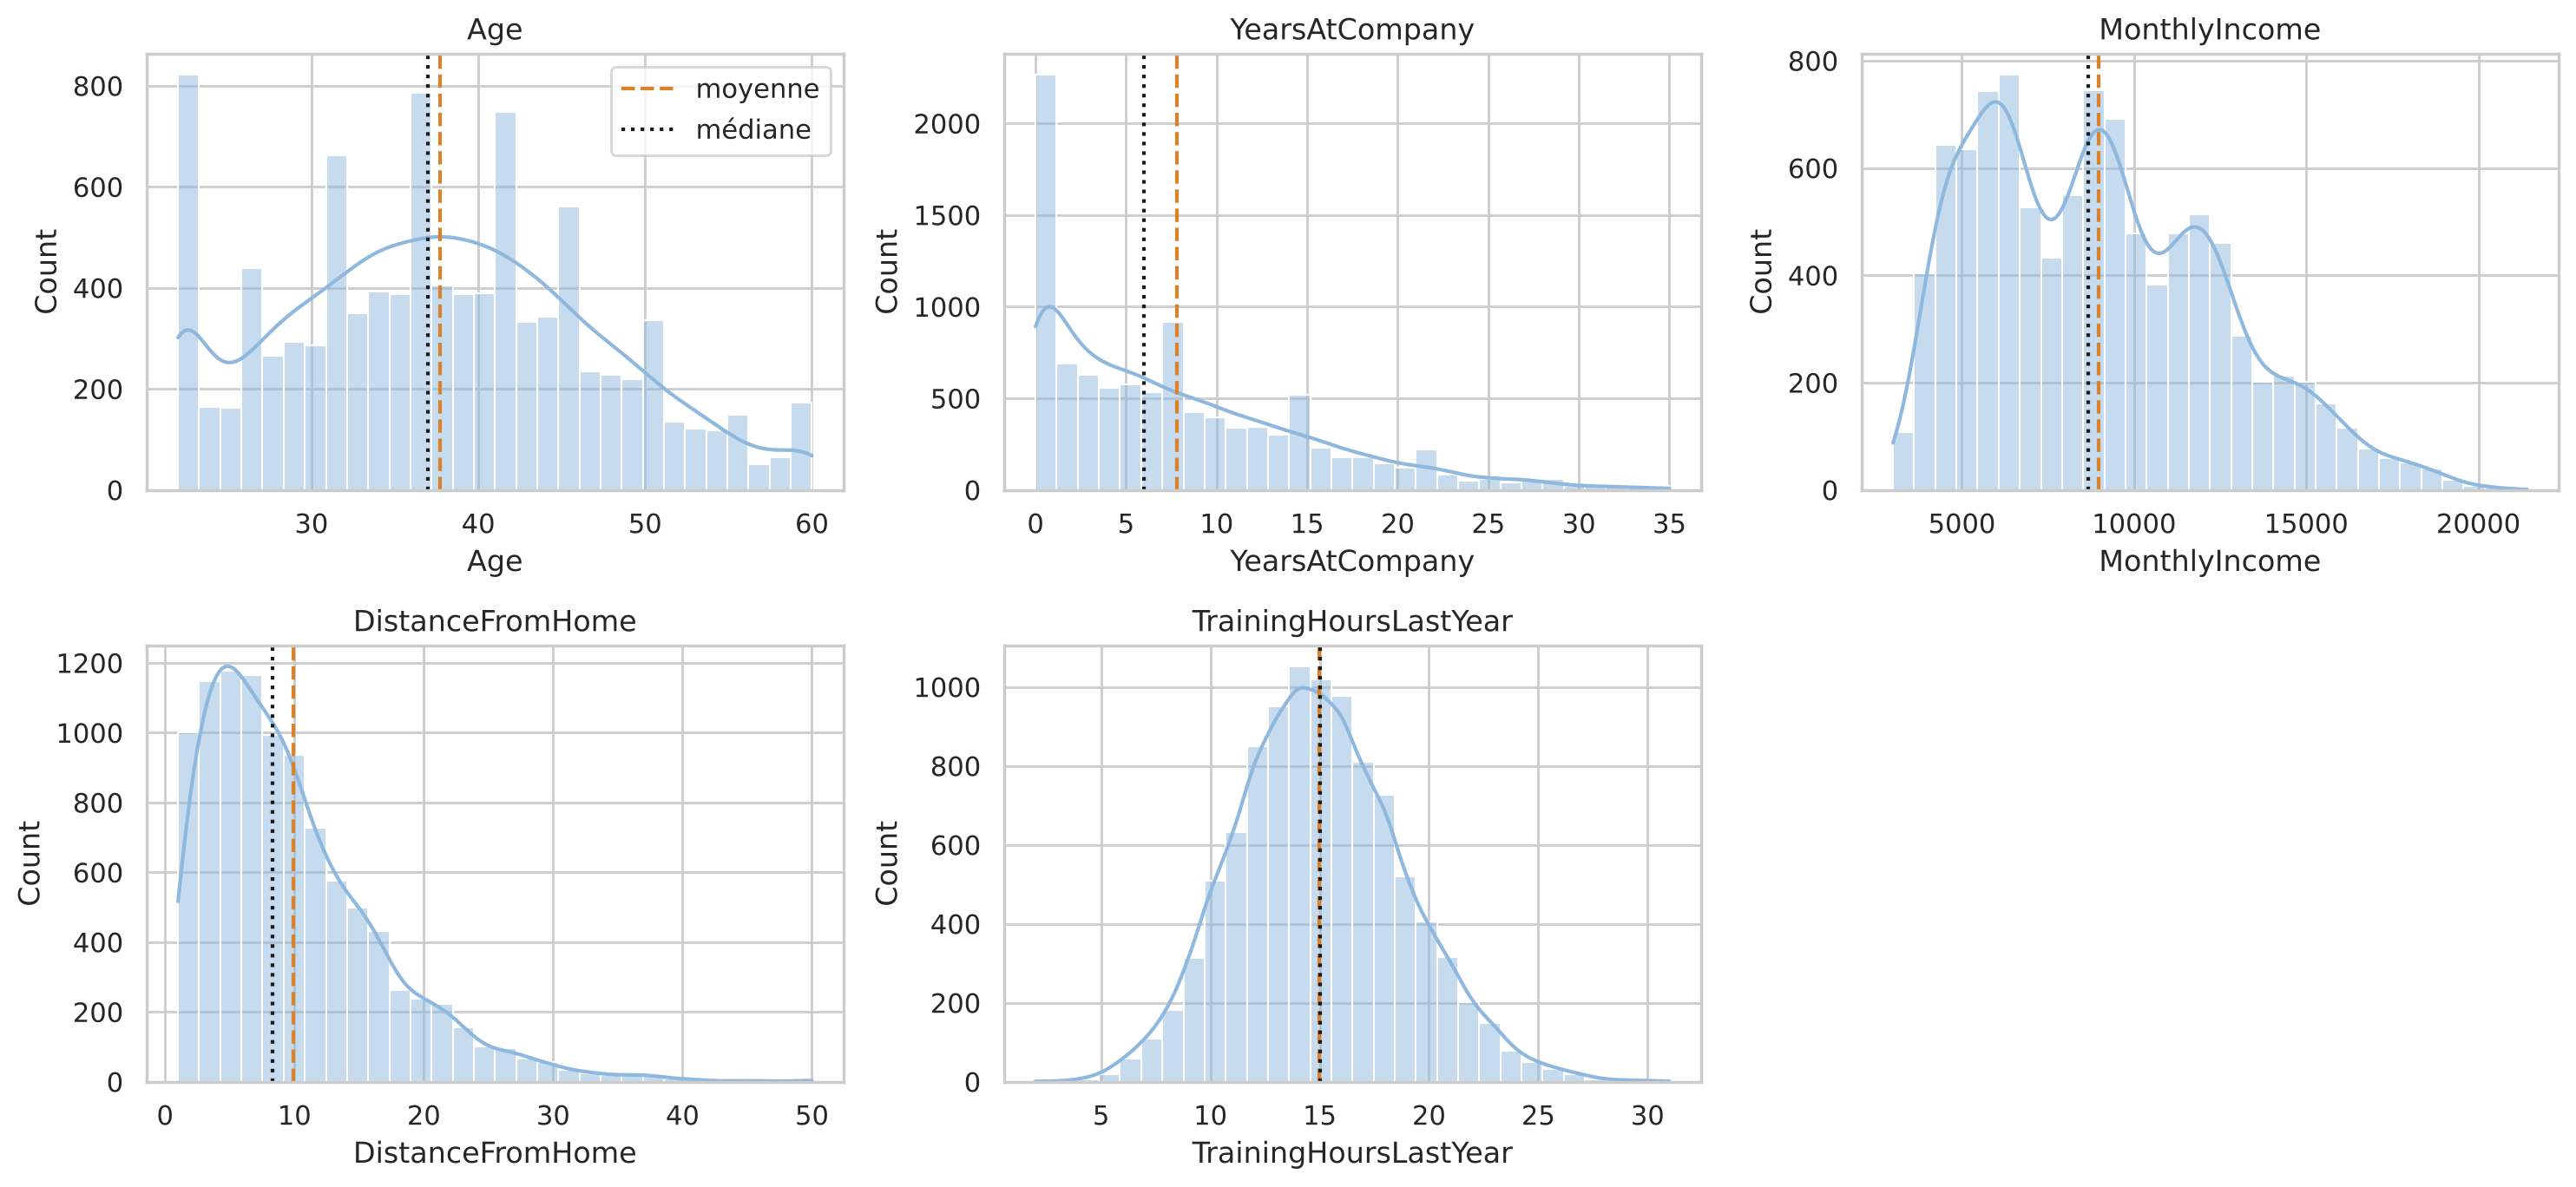

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, NUMERIC_COLS):
    sns.histplot(df[col], kde=True, bins=30, ax=ax, color=BLUE)
    ax.axvline(df[col].mean(), color=ORANGE, ls="--", label="moyenne")
    ax.axvline(df[col].median(), color="k", ls=":", label="médiane")
    ax.set_title(col)
axes.flat[0].legend(); axes.flat[-1].axis("off")
plt.tight_layout(); savefig("02_distributions_numeriques.png"); plt.show()

**Lecture.** `Age` et `TrainingHoursLastYear` sont presque symétriques ; `YearsAtCompany`, `DistanceFromHome` et `MonthlyIncome` sont asymétriques à droite (queue de valeurs élevées). Cela justifiera les tests non paramétriques (§ 7.1).

### Distributions selon le départ (densités comparées)

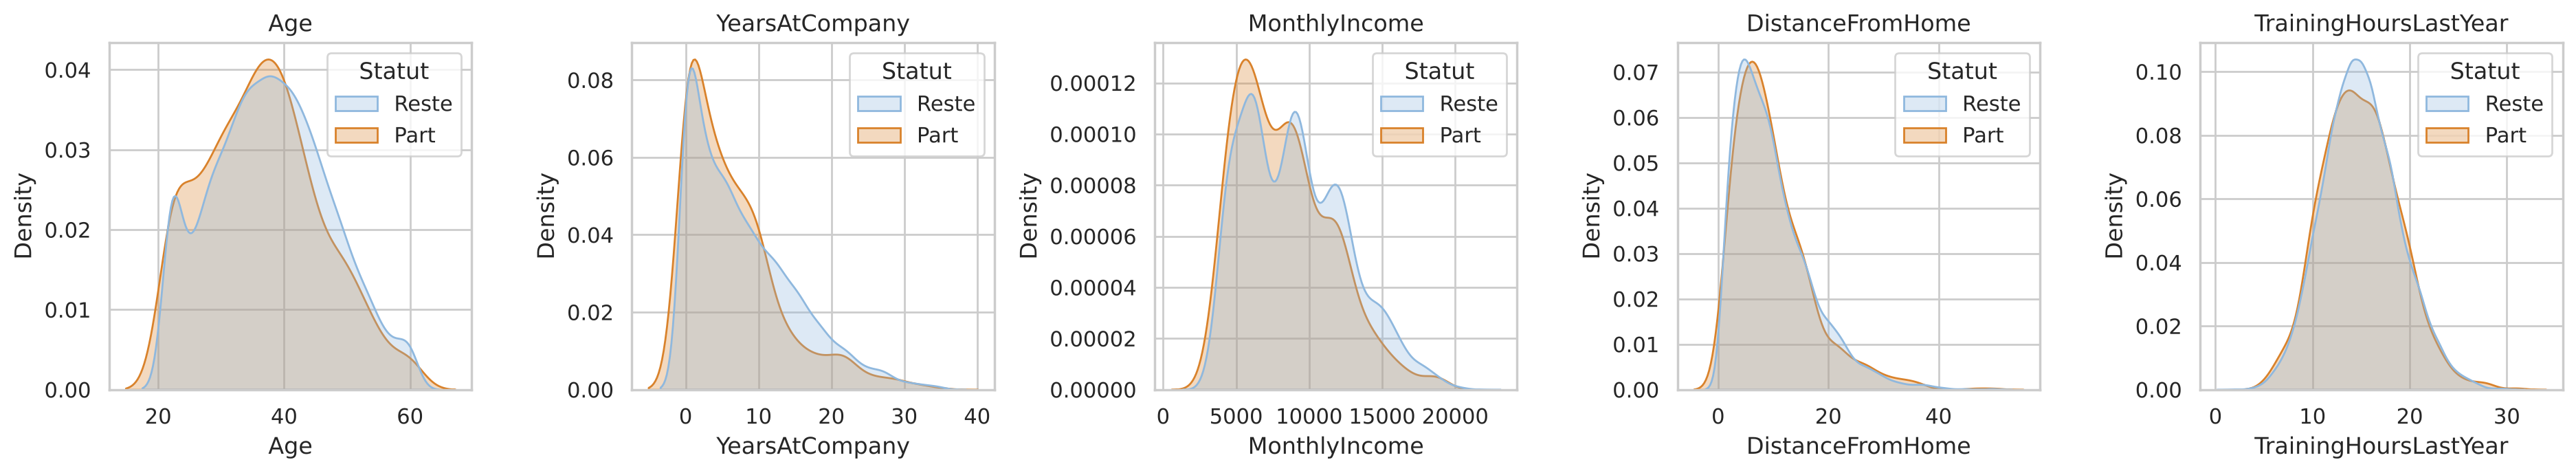

In [6]:
lab = df.assign(Statut=df[TARGET].map({0: "Reste", 1: "Part"}))
fig, axes = plt.subplots(1, 5, figsize=(19, 3.6))
for ax, col in zip(axes, NUMERIC_COLS):
    sns.kdeplot(data=lab, x=col, hue="Statut", hue_order=["Reste", "Part"], common_norm=False,
                palette=[BLUE, ORANGE], fill=True, alpha=.3, ax=ax)
    ax.set_title(col)
plt.tight_layout(); savefig("03_densites_par_attrition.png"); plt.show()

## 4. Fréquences des variables qualitatives
Pour chaque variable : effectifs (gauche) puis **taux de départ par modalité** (droite), à comparer au taux global.

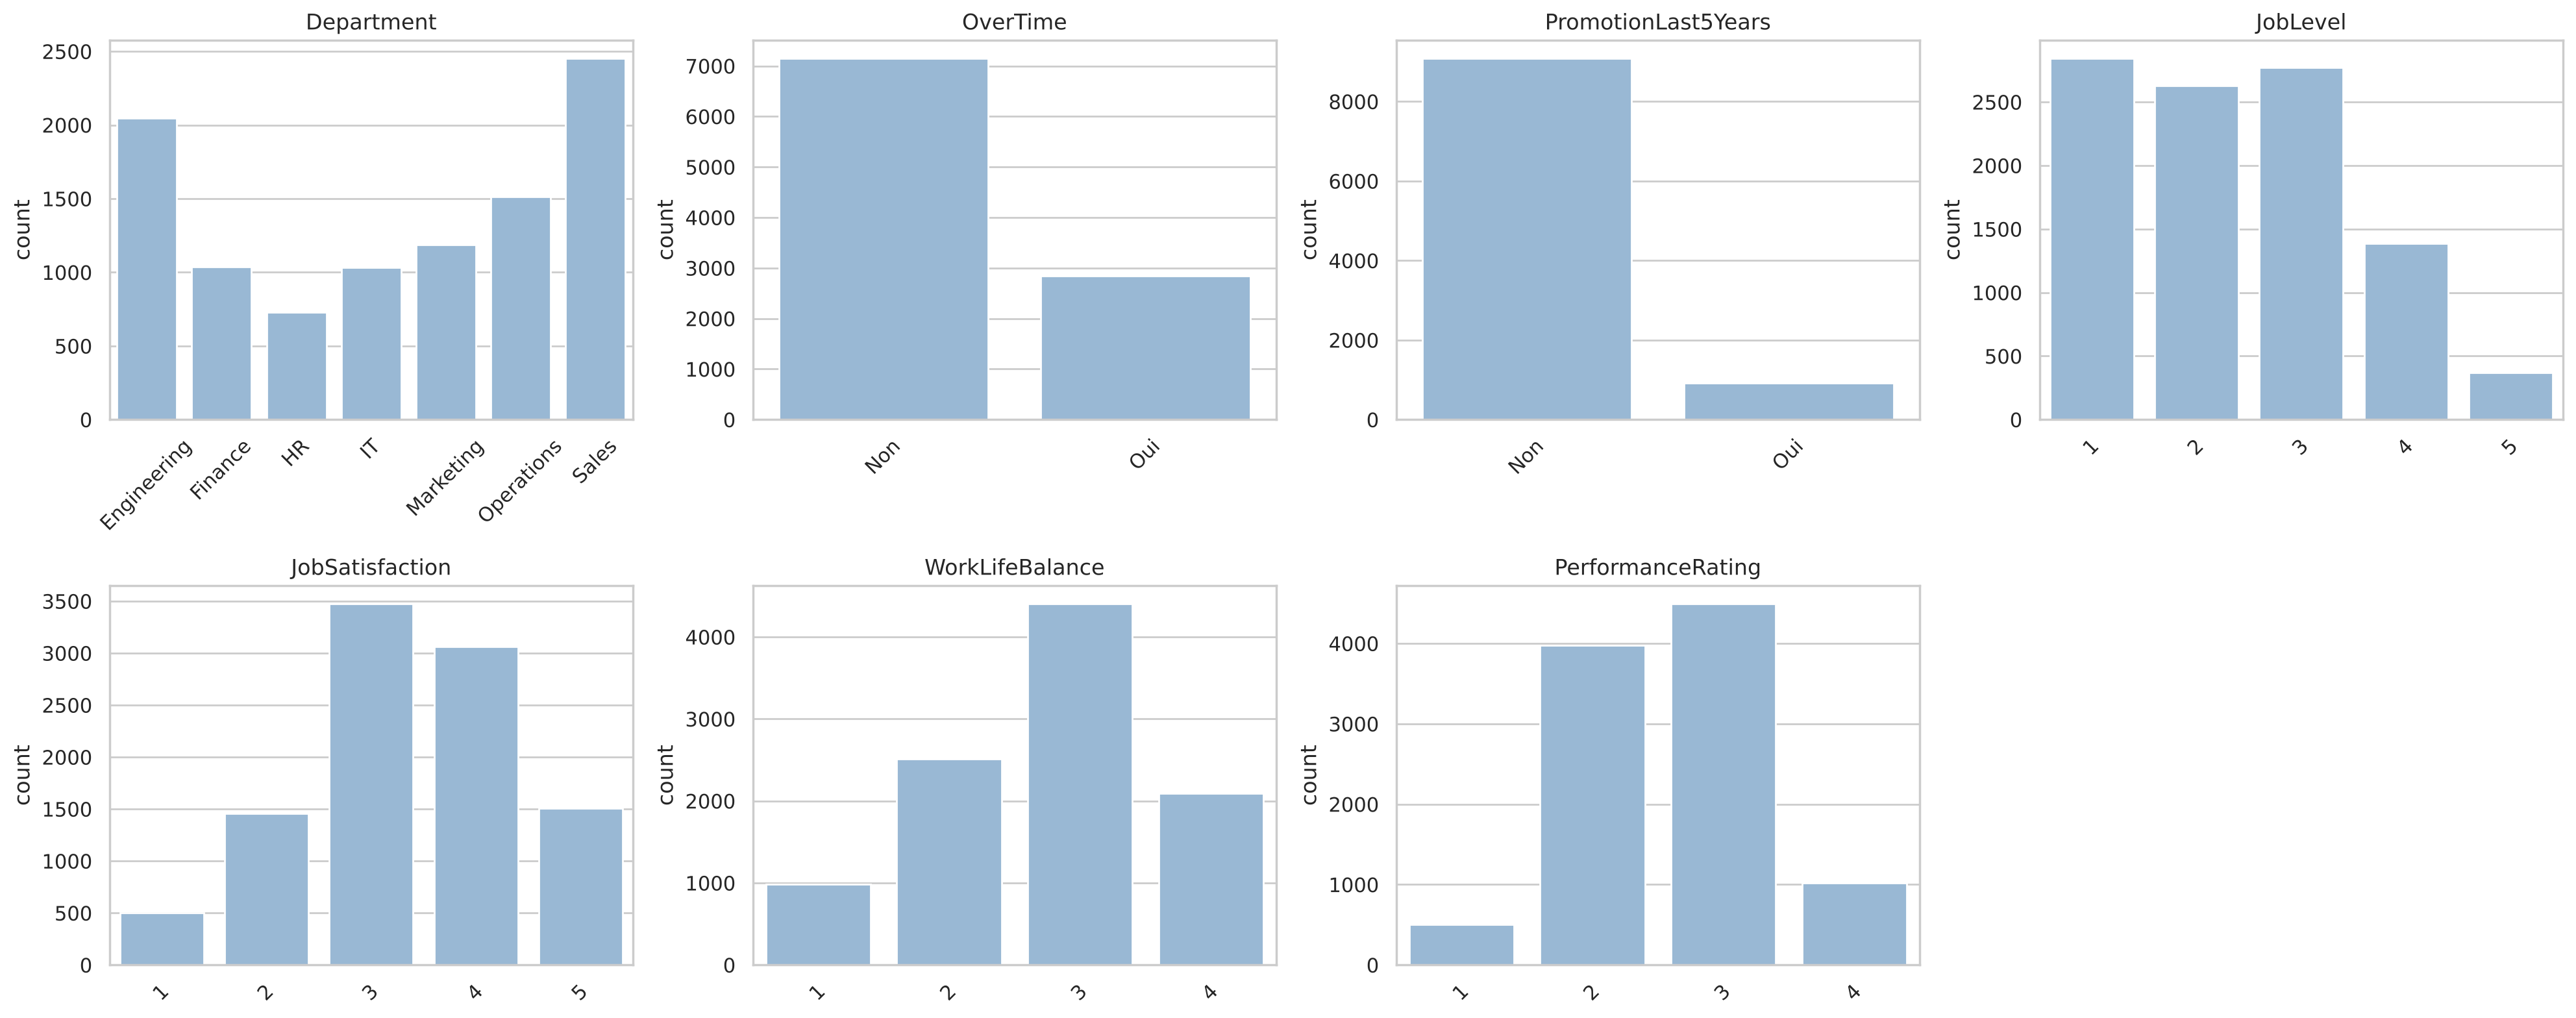

In [7]:
dv = df.copy()
for c in BINARY_COLS: dv[c] = dv[c].map({0: "Non", 1: "Oui"})
CATS_PLOT = NOMINAL_COLS + BINARY_COLS + ORDINAL_COLS
global_rate = df[TARGET].mean() * 100

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.flat, CATS_PLOT):
    order = sorted(dv[col].unique(), key=str)
    sns.countplot(data=dv, x=col, order=order, ax=ax, color=BLUE)
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=45)
axes.flat[-1].axis("off")
plt.tight_layout(); savefig("04_frequences_categorielles.png"); plt.show()

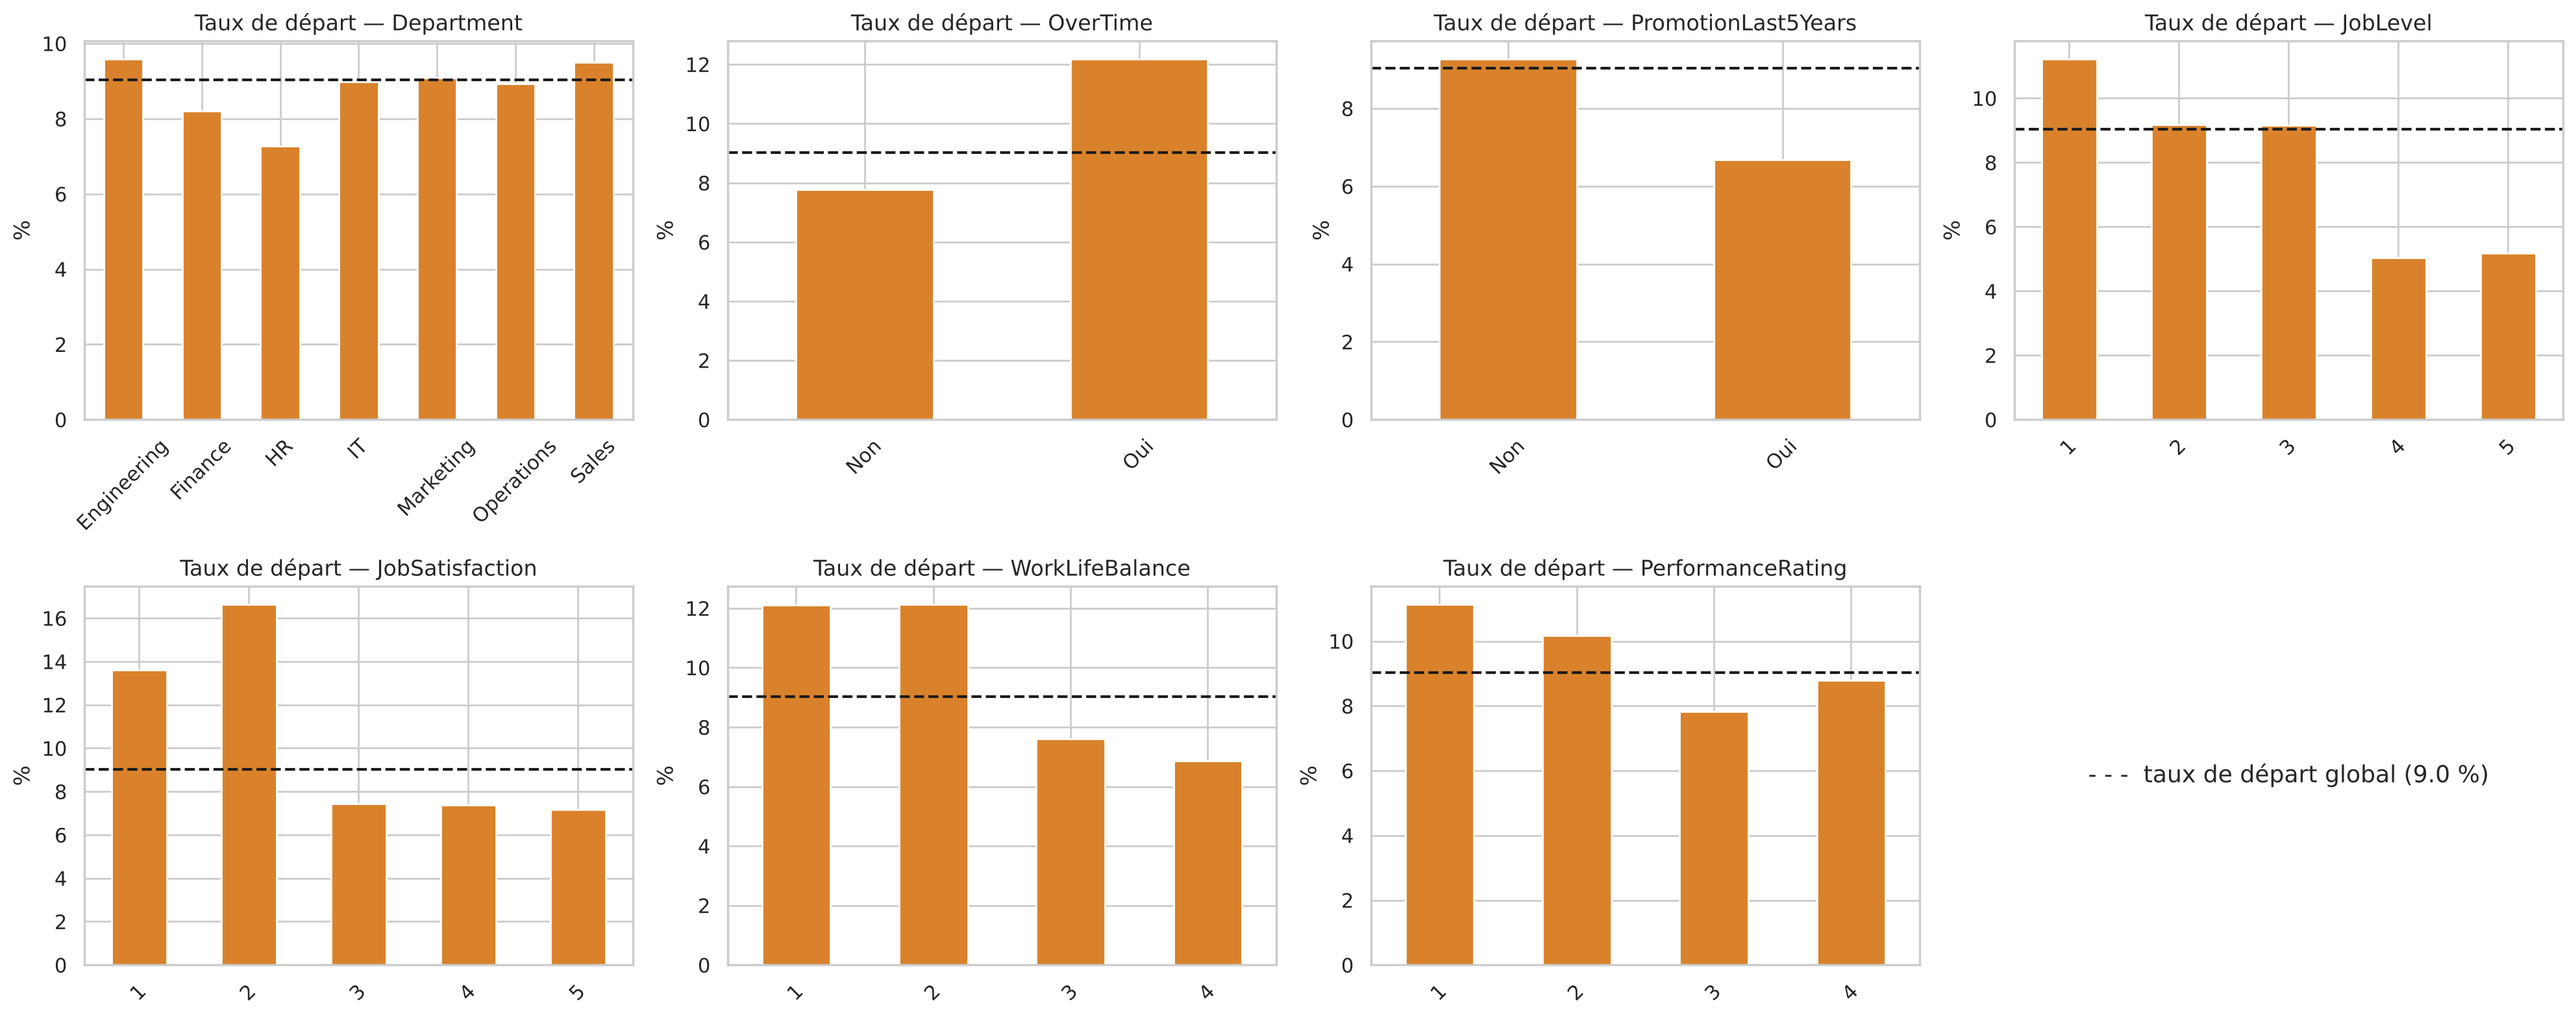

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.flat, CATS_PLOT):
    rate = dv.groupby(col)[TARGET].mean().mul(100)
    rate = rate.reindex(sorted(rate.index, key=str))
    rate.plot.bar(ax=ax, color=ORANGE, rot=45)
    ax.axhline(global_rate, color="k", ls="--")
    ax.set_title(f"Taux de départ — {col}"); ax.set_xlabel(""); ax.set_ylabel("%")
axes.flat[-1].axis("off")
axes.flat[-1].text(0.5, 0.5, f"- - -  taux de départ global ({global_rate:.1f} %)", ha="center", va="center", fontsize=13)
plt.tight_layout(); savefig("05_taux_depart_par_modalite.png"); plt.show()

**Lecture.** Le taux de départ global est ~9 %. Trois variables se démarquent visuellement :
- **Satisfaction** : ~14–17 % de départs aux niveaux 1–2, contre ~7 % aux niveaux 3–5.
- **Équilibre vie pro/perso** : ~12 % aux niveaux 1–2, ~7 % aux niveaux 3–4.
- **Heures supplémentaires** : 12,2 % (oui) contre 7,8 % (non).

Les effets semblent se jouer **par paliers** (seuils) plutôt que de façon linéaire : les modèles à base d'arbres devraient bien les capter. Le **département** varie peu (7–10 %).

## 5. Déséquilibre de la cible

In [9]:
vc = df[TARGET].value_counts().sort_index()
print(vc.rename({0: "Reste", 1: "Part"}).to_string())
print(f"Taux de départ : {df[TARGET].mean():.2%} | Ratio de déséquilibre : 1 pour {vc[0] / vc[1]:.1f}")
print(f"Accuracy du Zero-R (toujours 'reste') : {vc[0] / vc.sum():.2%}")

Attrition
Reste    9097
Part      903
Taux de départ : 9.03% | Ratio de déséquilibre : 1 pour 10.1
Accuracy du Zero-R (toujours 'reste') : 90.97%


## 6. Corrélations (Spearman)
On utilise **Spearman** et non Pearson : les variables sont ordinales ou asymétriques, et la relation visée est monotone, pas forcément linéaire.

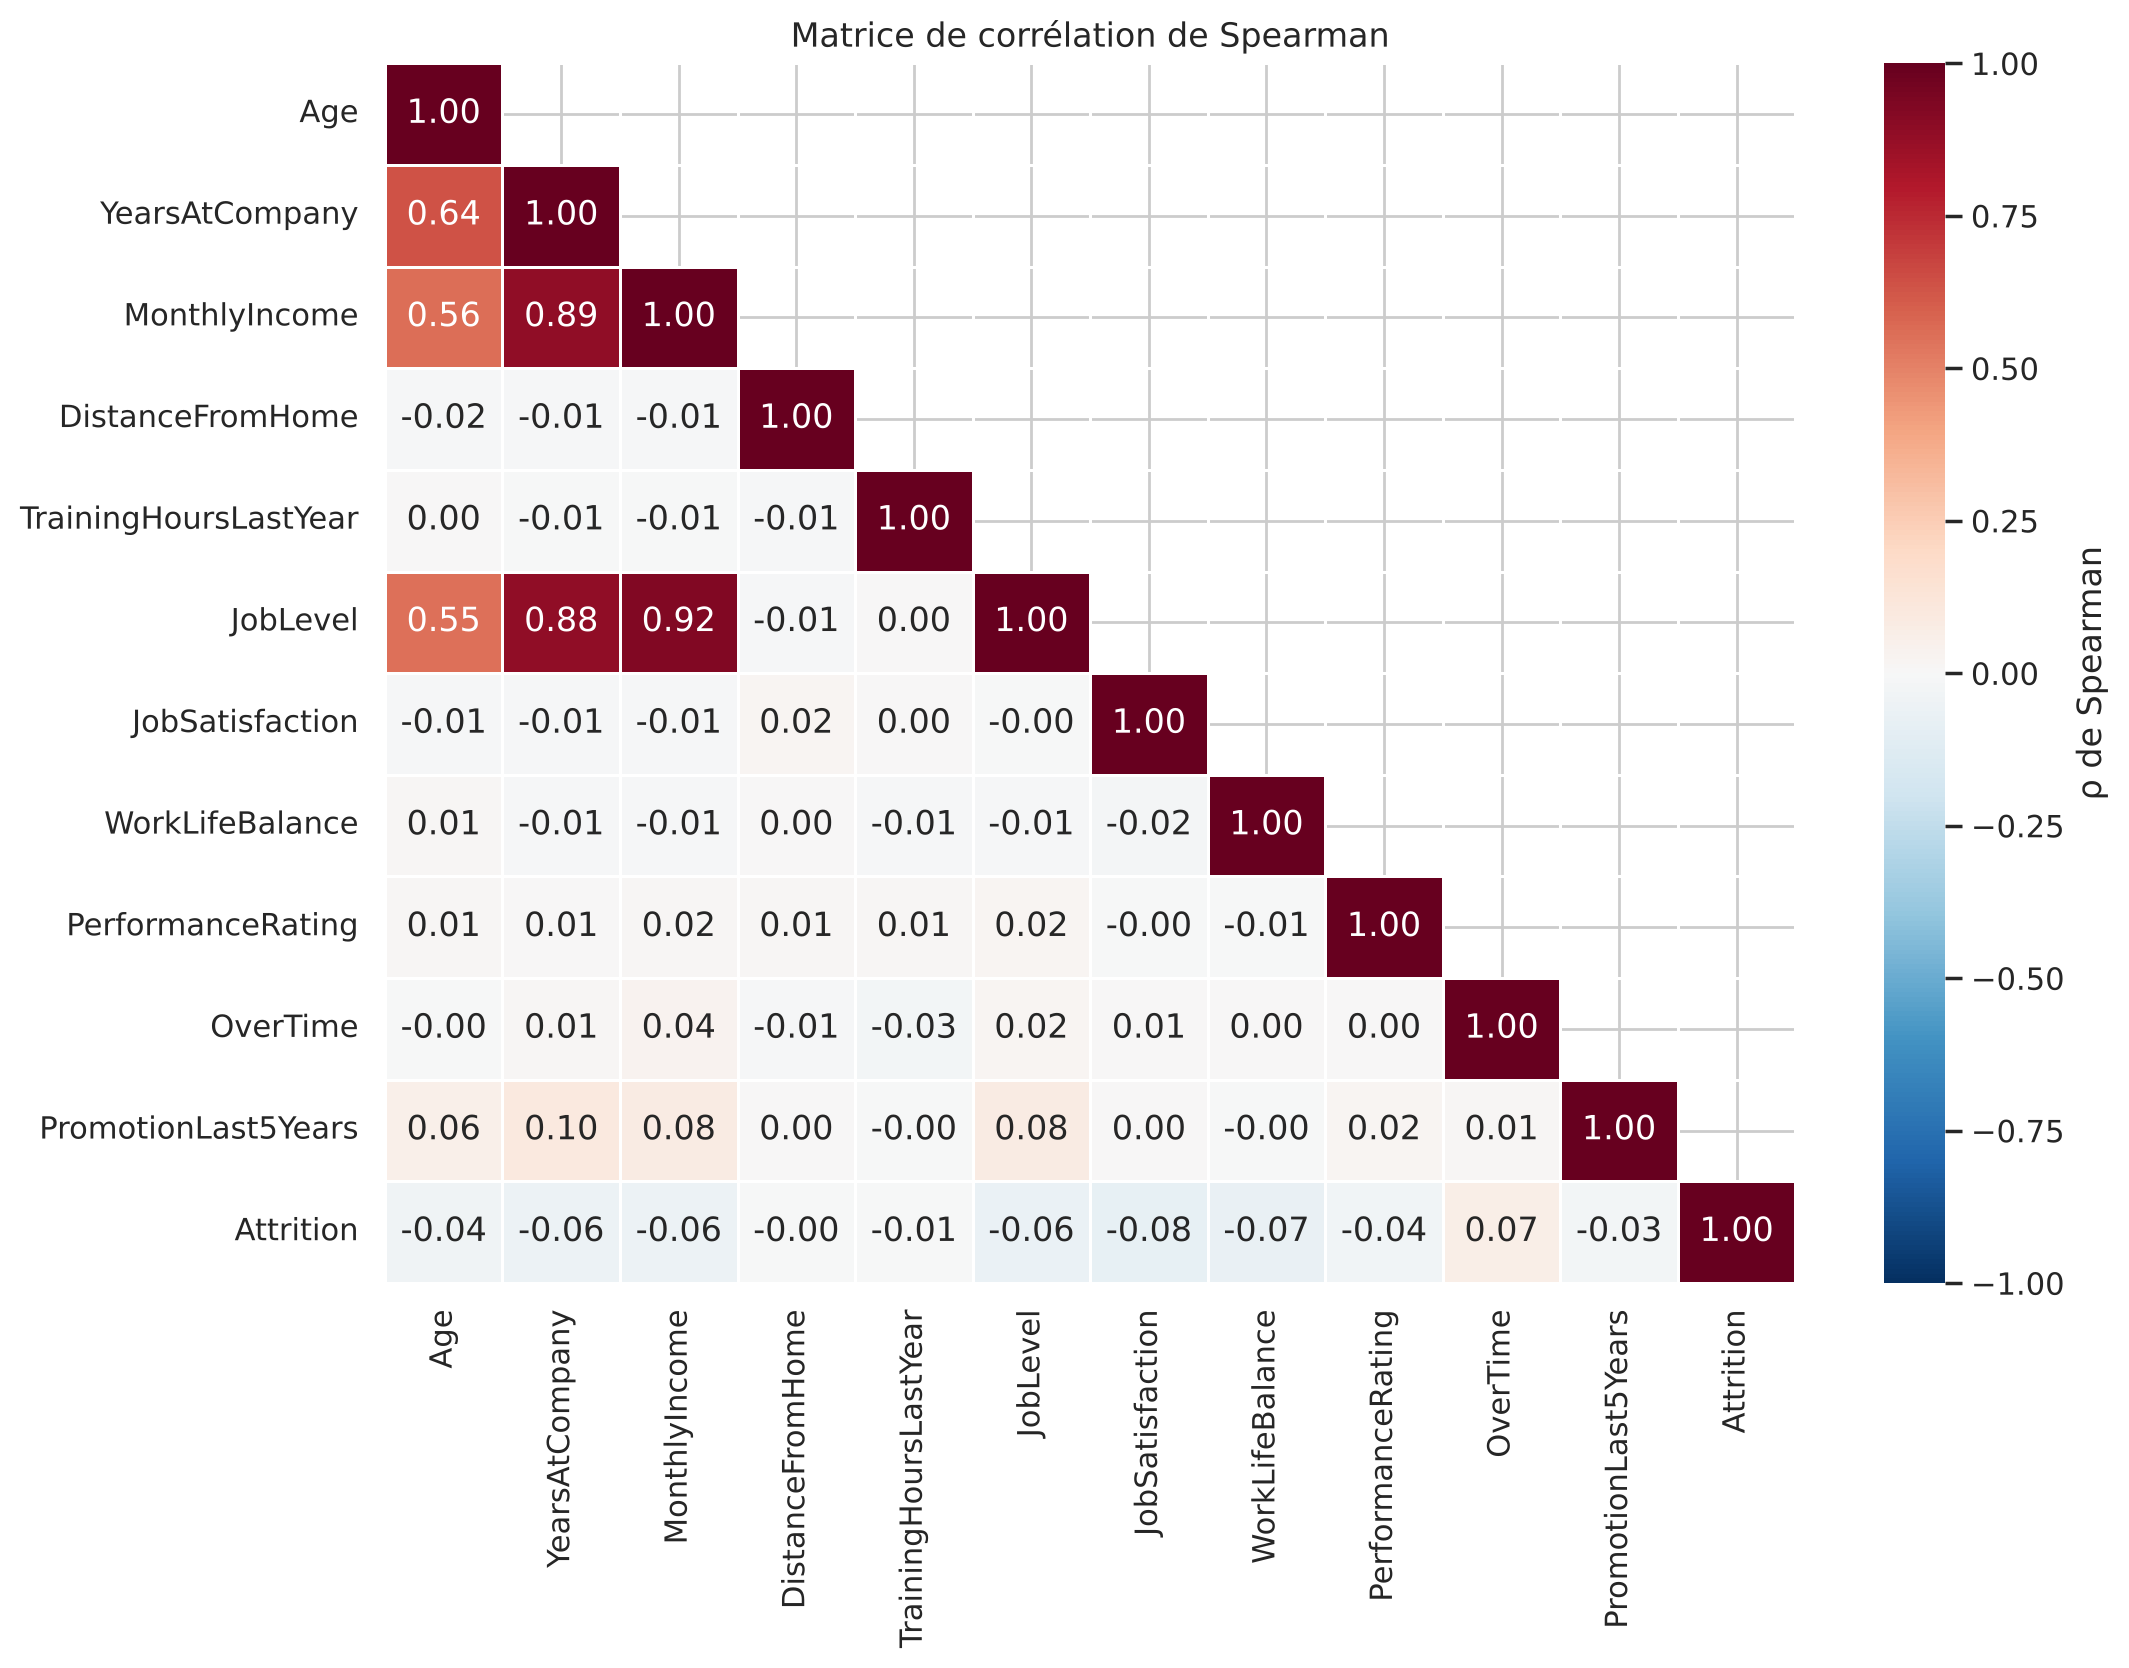

In [10]:
cols_corr = NUMERIC_COLS + ORDINAL_COLS + BINARY_COLS + [TARGET]
corr = df[cols_corr].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, linewidths=.5, ax=ax,
            cbar_kws={"label": "ρ de Spearman"})
ax.set_title("Matrice de corrélation de Spearman")
plt.tight_layout(); savefig("06_correlation_spearman.png"); plt.show()

**Lecture.** Un bloc très corrélé apparaît : `JobLevel`, `MonthlyIncome` et `YearsAtCompany` (ρ de 0,88 à 0,92), et dans une moindre mesure `Age`. À l'inverse, les corrélations de chaque variable avec `Attrition` sont toutes faibles (|ρ| < 0,10) — un signal diffus, pas une variable dominante.

---
# 7. Tests statistiques
Seuil α = 0,05. Quand plusieurs tests répondent à la même question (ici : *qu'est-ce qui est associé au départ ?*), on corrige les p-values par **Benjamini-Hochberg (FDR)** pour contrôler la proportion de faux positifs. Avec n = 10 000, même un effet minuscule devient « significatif » : on rapporte donc toujours une **taille d'effet** à côté de la p-value.

## 7.1 Normalité — Shapiro-Wilk
**Pourquoi ?** Choisir entre tests paramétriques (t, ANOVA) et non paramétriques. *H0 : la variable suit une loi normale.* Shapiro-Wilk est le test de normalité le plus puissant à ce volume, mais n'est fiable que jusqu'à ~5 000 observations : on teste un échantillon aléatoire reproductible de 5 000 lignes.

In [11]:
sw = shapiro_table(df, NUMERIC_COLS)
sw.to_csv(RES / "stat_normalite_shapiro.csv")
sw

,n_teste,W,p_value,asymetrie,aplatissement,normale (p>0.05)
variable,,,,,,
Age,5000,0.9791,1.595e-26,0.1977,-0.5946,False
YearsAtCompany,5000,0.9017,6.337e-49,1.026,0.594,False
MonthlyIncome,5000,0.9646,2.326e-33,0.5398,-0.3665,False
DistanceFromHome,5000,0.893,2.392e-50,1.345,2.396,False
TrainingHoursLastYear,5000,0.9889,2.242e-19,0.2603,0.05718,False


**Interprétation.** La normalité est rejetée pour les 5 variables (p < 0,001). Avec un grand échantillon, Shapiro rejette dès qu'il y a un écart minime, donc on s'appuie aussi sur l'asymétrie : forte pour `DistanceFromHome` (1,34) et `YearsAtCompany` (1,03), modérée pour `MonthlyIncome`, faible pour `Age` et `TrainingHoursLastYear`. **Conclusion : tests non paramétriques** (Mann-Whitney, Kruskal-Wallis, Spearman), aussi adaptés aux échelles ordinales 1–5.

## 7.2 Variables quantitatives / ordinales vs départ — Mann-Whitney U
**Pourquoi ?** Comparer deux groupes **indépendants** (partants / restants) sur une variable non normale ou ordinale. *H0 : les deux groupes ont la même distribution.* **Taille d'effet** : corrélation bisériale par rangs *r* (négatif = valeurs plus faibles chez ceux qui partent).

## 7.3 Variables qualitatives vs départ — Khi-deux d'indépendance
**Pourquoi ?** Tester l'association entre deux variables qualitatives (`Department`, `OverTime`, `PromotionLast5Years` × `Attrition`). *H0 : indépendance.* Condition de validité : effectifs théoriques ≥ 5 dans chaque case (vérifiée). **Taille d'effet** : V de Cramér.

In [12]:
mw = mannwhitney_table(df, QUANT, TARGET)
ch = chi2_table(df, CATEG, TARGET)
print("Condition khi-deux (effectifs théoriques ≥ 5) :", bool(ch["condition_valide (>=5)"].all()))

res = pd.DataFrame({
    "test": ["Mann-Whitney U"] * len(mw) + ["Khi-deux"] * len(ch),
    "statistique": list(mw["U"]) + list(ch["chi2"]),
    "p_value": list(mw["p_value"]) + list(ch["p_value"]),
    "effet": list(mw["effet_r_biserial"].abs()) + list(ch["V_Cramer"]),
    "mesure_effet": ["|r| biserial"] * len(mw) + ["V de Cramér"] * len(ch),
    "sens": list(np.where(mw["effet_r_biserial"] > 0, "↑ chez les partants", "↓ chez les partants")) + [""] * len(ch),
}, index=list(mw.index) + list(ch.index))
res = add_fdr(res)                                  # famille de 12 tests, correction BH
res["taille_effet"] = res["effet"].map(effect_label)
res = res.sort_values("effet", ascending=False)
res.to_csv(RES / "stat_tests_vs_attrition.csv")
res[["test", "p_value", "p_adj_BH", "significatif", "effet", "mesure_effet", "taille_effet", "sens"]]

Condition khi-deux (effectifs théoriques ≥ 5) : True


,test,p_value,p_adj_BH,significatif,effet,mesure_effet,taille_effet,sens
JobSatisfaction,Mann-Whitney U,2.662e-17,3.194e-16,True,0.1637,|r| biserial,faible,↓ chez les partants
WorkLifeBalance,Mann-Whitney U,1.797e-13,1.078e-12,True,0.1398,|r| biserial,faible,↓ chez les partants
JobLevel,Mann-Whitney U,2.655e-10,7.966e-10,True,0.1231,|r| biserial,faible,↓ chez les partants
YearsAtCompany,Mann-Whitney U,1.666e-09,3.998e-09,True,0.1211,|r| biserial,faible,↓ chez les partants
MonthlyIncome,Mann-Whitney U,4.851e-09,9.701e-09,True,0.1179,|r| biserial,faible,↓ chez les partants
Age,Mann-Whitney U,6.839e-05,0.0001172,True,0.08016,|r| biserial,négligeable,↓ chez les partants
OverTime,Khi-deux,5.279e-12,2.112e-11,True,0.06898,V de Cramér,négligeable,
PerformanceRating,Mann-Whitney U,0.0004111,0.0006166,True,0.06542,|r| biserial,négligeable,↓ chez les partants
PromotionLast5Years,Khi-deux,0.01088,0.0145,True,0.02547,V de Cramér,négligeable,
Department,Khi-deux,0.5343,0.5829,False,0.02253,V de Cramér,négligeable,


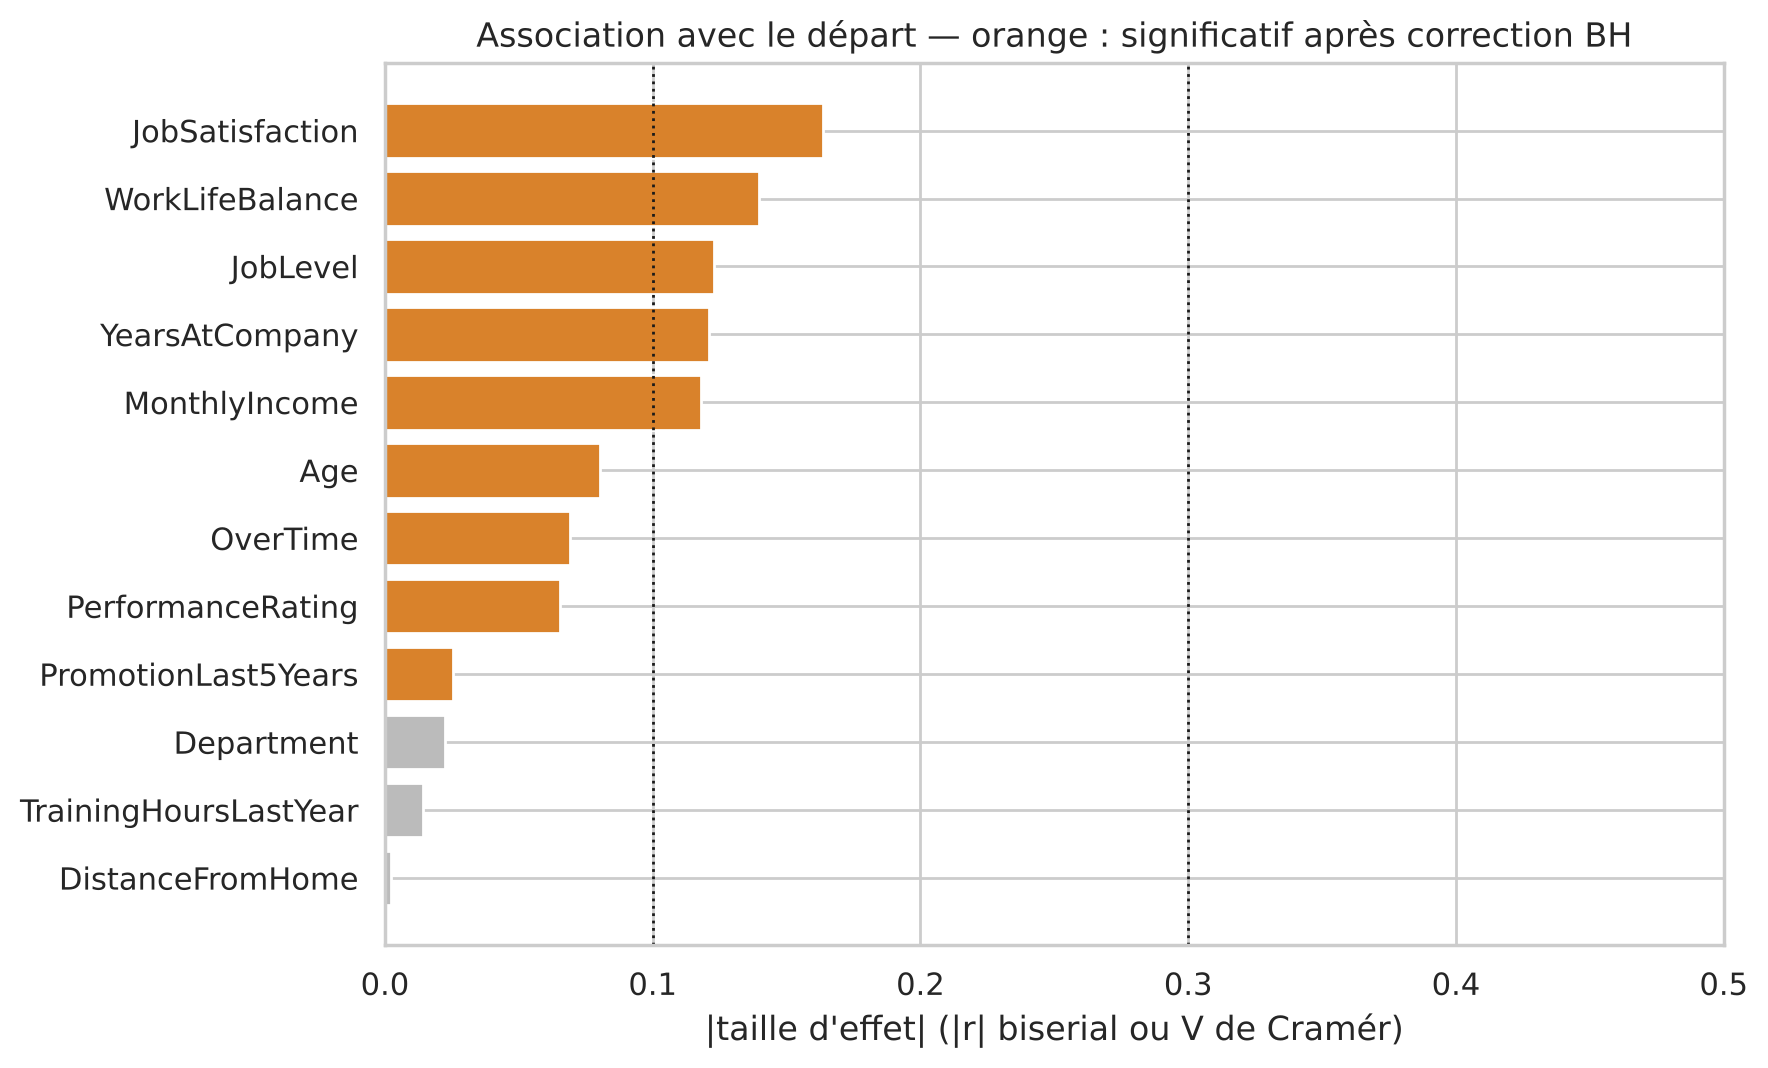

In [13]:
fig, ax = plt.subplots(figsize=(9, 5.5))
r = res.iloc[::-1]
ax.barh(r.index, r["effet"], color=[ORANGE if s else "#bbbbbb" for s in r["significatif"]])
for x in (0.1, 0.3): ax.axvline(x, color="k", ls=":", lw=1)
ax.set_xlabel("|taille d'effet| (|r| biserial ou V de Cramér)")
ax.set_title("Association avec le départ — orange : significatif après correction BH")
ax.set_xlim(0, 0.5)
plt.tight_layout(); savefig("07_taille_effet_vs_attrition.png"); plt.show()

**Interprétation (12 tests, FDR 5 %).**
- **9 associations significatives** : `JobSatisfaction`, `WorkLifeBalance`, `JobLevel`, `YearsAtCompany`, `MonthlyIncome`, `Age`, `PerformanceRating`, `OverTime`, `PromotionLast5Years`. Les partants ont des niveaux plus **faibles** de satisfaction, d'équilibre, de niveau de poste, d'ancienneté, de salaire et d'âge, font plus d'heures supplémentaires et ont été moins souvent promus au cours des 5 dernières années.
- **3 non significatives** : `DistanceFromHome`, `TrainingHoursLastYear`, `Department`.
- **Mais toutes les tailles d'effet sont faibles ou négligeables** (|r| ≤ 0,16 ; V ≤ 0,07). La significativité vient surtout de la taille de l'échantillon. Aucune variable ne sépare à elle seule les partants des restants : on peut s'attendre à des performances de modèles **modérées**, et la comparaison au Zero-R devra se faire sur F1 / PR-AUC, pas sur l'accuracy.

## 7.4 Plus de deux groupes — Kruskal-Wallis
**Pourquoi ?** Comparer une variable quantitative non normale entre plus de 2 groupes (alternative non paramétrique à l'ANOVA à un facteur). *H0 : les groupes ont la même distribution.* **Taille d'effet** : ε². On teste si le salaire dépend du niveau de poste et du département (cohérence métier et redondance entre variables).

In [14]:
kw = kruskal_table(df, "MonthlyIncome", ["JobLevel", "Department"])
kw.to_csv(RES / "stat_kruskal_wallis.csv")
kw

,variable_quanti,k_groupes,H,p_value,epsilon2
facteur,,,,,
JobLevel,MonthlyIncome,5,8531,0,0.8532
Department,MonthlyIncome,7,997.1,3.715e-212,0.09918


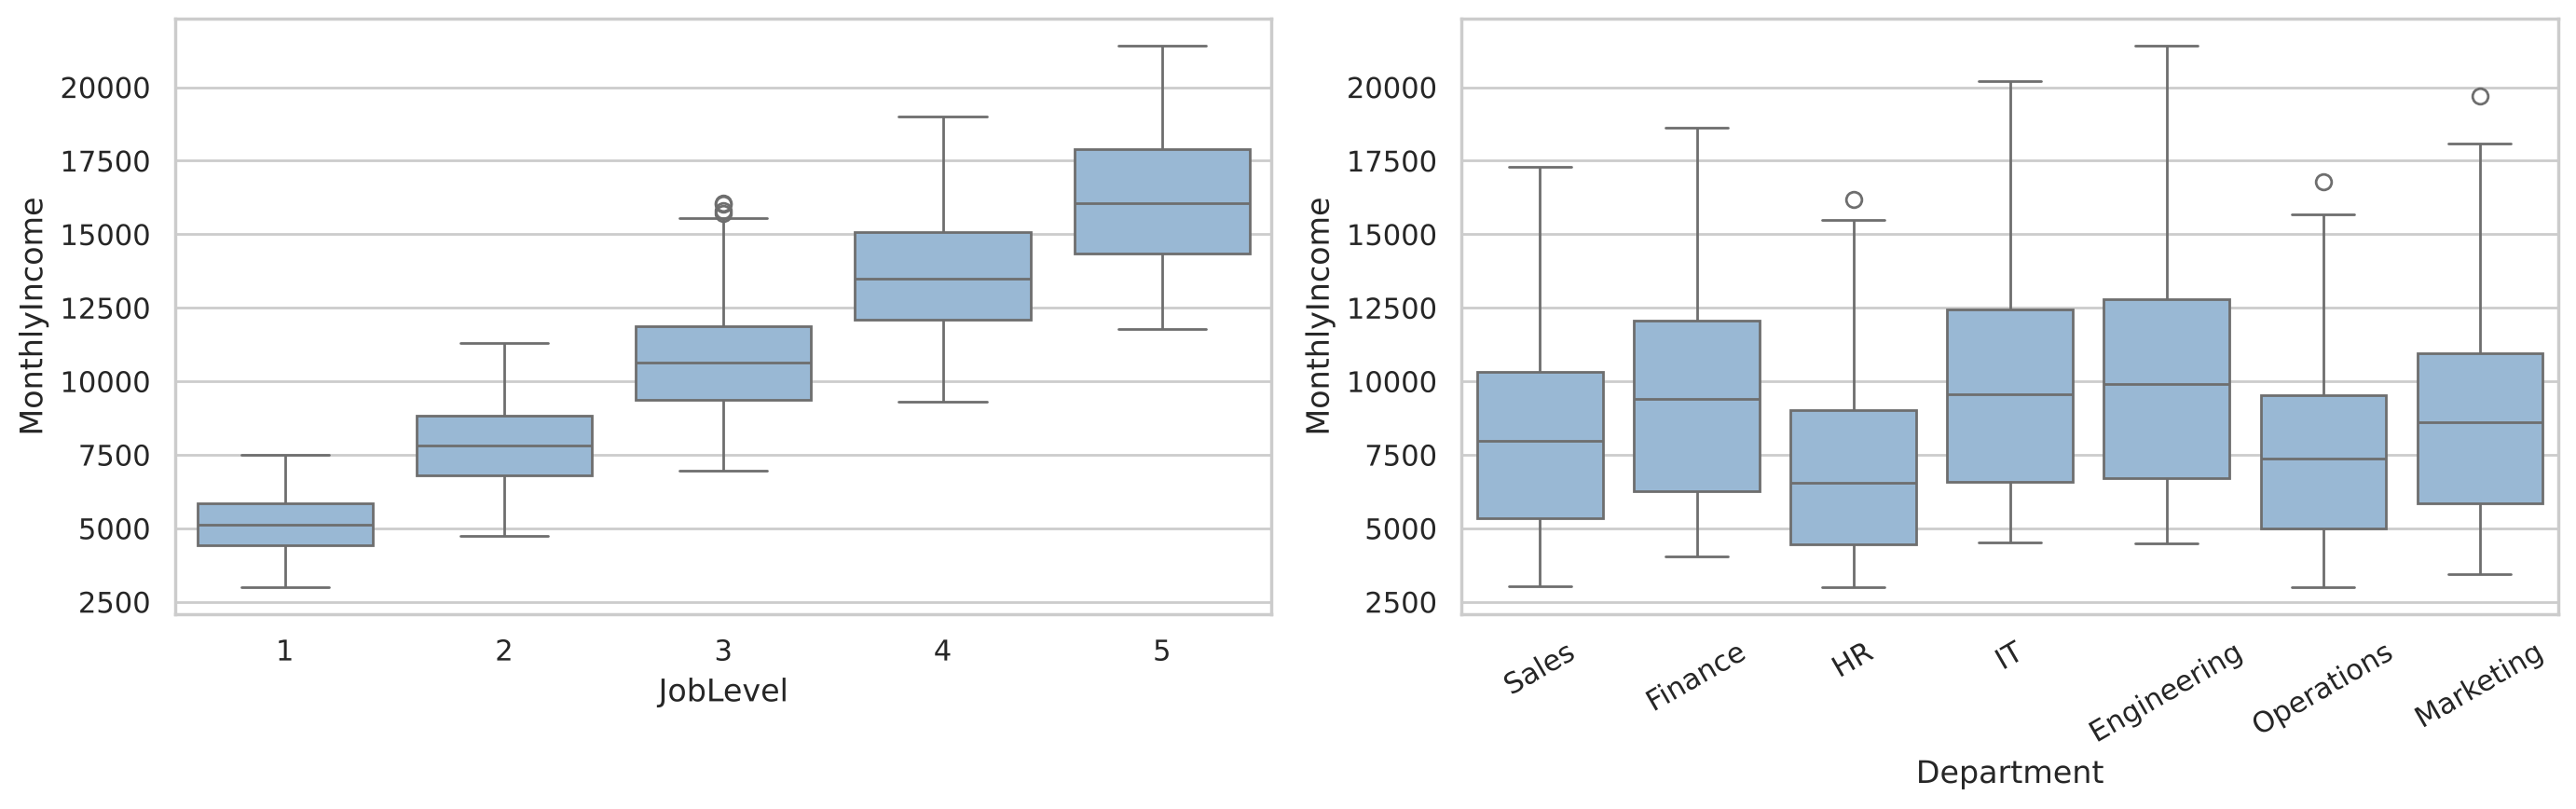

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x="JobLevel", y="MonthlyIncome", ax=axes[0], color=BLUE)
sns.boxplot(data=df, x="Department", y="MonthlyIncome", ax=axes[1], color=BLUE)
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); savefig("08_revenu_par_niveau_departement.png"); plt.show()

**Interprétation.** Le revenu dépend très fortement du niveau de poste (ε² ≈ 0,85, effet fort) et nettement moins du département (ε² ≈ 0,10, effet moyen). `JobLevel` et `MonthlyIncome` portent donc en grande partie la **même information**.

## 7.5 Corrélation — Spearman avec p-value
**Pourquoi ?** Mesurer la force d'une relation monotone entre deux variables ordinales ou non normales. *H0 : ρ = 0.* On cherche ici les paires de variables explicatives très liées (|ρ| ≥ 0,7).

In [16]:
sp_all = spearman_pairs(df, QUANT + BINARY_COLS)
sp_all = add_fdr(sp_all)
sp_all.to_csv(RES / "stat_spearman_paires.csv", index=False)
print("Paires de variables explicatives avec |ρ| ≥ 0,7 :")
sp_all[sp_all["|rho|"] >= 0.7][["var_1", "var_2", "rho", "p_value", "p_adj_BH"]]

Paires de variables explicatives avec |ρ| ≥ 0,7 :


,var_1,var_2,rho,p_value,p_adj_BH
0,MonthlyIncome,JobLevel,0.9234,0,0
1,YearsAtCompany,MonthlyIncome,0.8866,0,0
2,YearsAtCompany,JobLevel,0.883,0,0


**Interprétation.** Trois paires dépassent 0,7 : `MonthlyIncome`–`JobLevel` (0,92), `YearsAtCompany`–`MonthlyIncome` (0,89) et `YearsAtCompany`–`JobLevel` (0,88). **Conséquences pour la modélisation :**
- **Naïve Bayes** suppose l'indépendance conditionnelle des variables : cette hypothèse est ici violée, ses probabilités seront peu fiables.
- **K-NN** compte la même information trois fois dans la distance (la standardisation ne règle pas la redondance).
- **Arbres / Random Forest** sont robustes, mais l'importance des variables sera répartie entre variables corrélées : à interpréter avec précaution.
- **SVM** reste utilisable ; la régularisation (`C`) limite l'effet.

---
# 8. Synthèse et décisions pour la suite

| Constat | Décision |
|---|---|
| Données propres (0 manquant, 0 doublon) | Pipeline de prétraitement déjà prêt (notebook 02) |
| Cible déséquilibrée (~9 % de départs, Zero-R ≈ 91 % d'accuracy) | Optimiser **F1 / average precision** dans `GridSearchCV` ; pondération des classes ; lire le rappel de la classe « part » |
| Variables non normales | Tests non paramétriques ; standardisation Z-score pour K-NN, SVM, Naïve Bayes |
| Signal faible mais réel (|r| ≤ 0,16 ; V ≤ 0,07) | Attendre des performances modérées ; comparer à Zero-R ; ne pas promettre d'accuracy élevée |
| Effets par paliers (satisfaction, équilibre, heures sup.) | Les arbres / Random Forest devraient bien performer |
| Bloc colinéaire `JobLevel`–`MonthlyIncome`–`YearsAtCompany` | Prudence pour Naïve Bayes et l'interprétation des importances ; tester un jeu de variables réduit |
| `DistanceFromHome`, `TrainingHoursLastYear`, `Department` non significatifs | On les **garde** pour l'instant ; leur utilité sera jugée sur le train (importance par permutation), pas par ces tests |

**Tests réalisés (tous justifiés) :** Shapiro-Wilk, Mann-Whitney U, Khi-deux + V de Cramér, Kruskal-Wallis, Spearman — avec correction Benjamini-Hochberg sur la famille des 12 tests contre la cible.